In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler

df = pd.read_csv('../pliki/water-potability.csv')
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


### wyznaczenie zmiennych zaleznych y i niezaleznych X. podział na zbiory

In [32]:
X = df.drop(columns=['Potability'])
y = df['Potability']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print(X_train.shape)
print(X_test.shape)

(2620, 9)
(656, 9)


### Sprawdzenie braków

In [33]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


In [34]:
df.isnull().sum()

ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

In [35]:
df.isna().mean().sort_values(ascending=False)

Sulfate            0.238400
ph                 0.149878
Trihalomethanes    0.049451
Hardness           0.000000
Chloramines        0.000000
Solids             0.000000
Conductivity       0.000000
Organic_carbon     0.000000
Turbidity          0.000000
Potability         0.000000
dtype: float64

### uzupelniam brakujące wartości medianą

In [36]:
# Wyznaczenie median dla wybranych kolumn wyłącznie ze zbioru treningowego
train_medians = X_train[['ph', 'Sulfate', 'Trihalomethanes']].median()

# Uzupełnienie braków bezpośrednio w obu zbiorach
X_train[['ph', 'Sulfate', 'Trihalomethanes']] = X_train[['ph', 'Sulfate', 'Trihalomethanes']].fillna(train_medians)
X_test[['ph', 'Sulfate', 'Trihalomethanes']] = X_test[['ph', 'Sulfate', 'Trihalomethanes']].fillna(train_medians)

print(X_train.isnull().sum())


ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
dtype: int64


### wykrywanie outlierów dla kolumny Sulfate

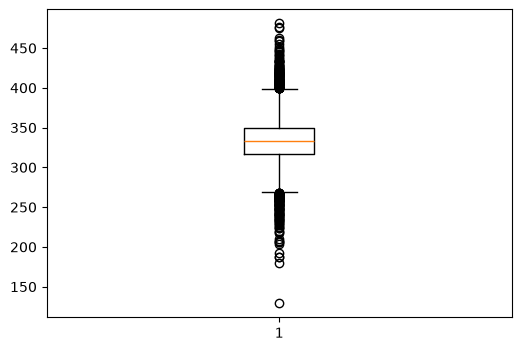

In [37]:
plt.figure(figsize=(6,4))
plt.boxplot(X_train["Sulfate"])
plt.show()

### metoda IQR

In [38]:
Q1 = X_train["Sulfate"].quantile(0.25)
Q3 = X_train["Sulfate"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = X_train[(X_train["Sulfate"] < lower) | (X_train["Sulfate" ] > upper)]
print(f"Liczba outlierów dla Sulfate w zbiorze treningowym: {len(outliers)}")

Liczba outlierów dla Sulfate w zbiorze treningowym: 225


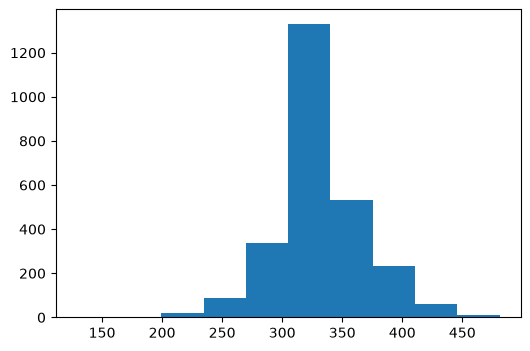

In [39]:
plt.figure(figsize=(6,4))
plt.hist(X_train["Sulfate"])
plt.show()

anomalie po obu stronach
### standaryzacja Z-score, aby nie kompresować sztucznie wyników

In [40]:
X_train_st, X_test_st = X_train.copy(), X_test.copy()
standard = StandardScaler()
X_train_st[X_train.columns] = standard.fit_transform(X_train_st[X_train.columns])
X_test_st[X_test.columns] = standard.transform(X_test_st[X_test.columns])

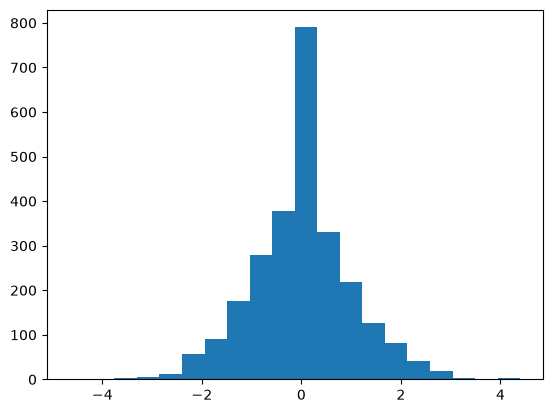

In [41]:
plt.hist(X_train_st["ph"], bins=20)
plt.show()

### macierz korelacji

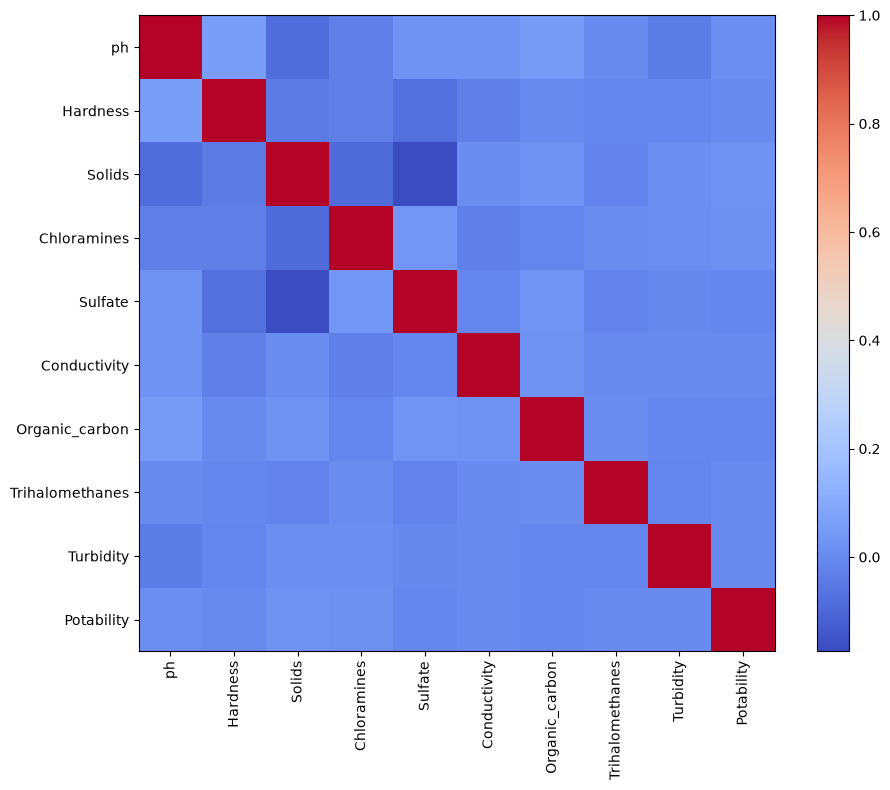

In [42]:
train_df = pd.concat([X_train_st, y_train], axis=1)
corr = train_df.select_dtypes(include=np.number).corr()
corr

plt.figure(figsize=(10,8))
plt.imshow(corr, cmap="coolwarm", interpolation="nearest")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.tight_layout()
plt.show()

In [43]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k=5)
X_train_selected = selector.fit_transform(X_train_st, y_train)
X_test_selected = selector.transform(X_test_st)

selected_features = X_train_st.columns[selector.get_support()]
print(selected_features)

final_train_df = pd.concat([pd.DataFrame(X_train_selected, columns=selected_features), y_train.reset_index(drop=True)], axis=1)
X_train_final = final_train_df.drop(columns=['Potability'])
y_train_final = final_train_df['Potability']

Index(['ph', 'Solids', 'Chloramines', 'Sulfate', 'Organic_carbon'], dtype='str')
